In [12]:
import os
from dotenv import load_dotenv
load_dotenv()
from langchain_groq import ChatGroq
from langchain_core.tools import tool
from langchain_tavily import TavilySearch
from typing import Annotated, TypedDict

In [13]:
from langgraph.graph import StateGraph, END, MessagesState
from langgraph.prebuilt import ToolNode, tools_condition
from langchain_core.messages import SystemMessage

In [23]:
#Define the State
class AgentState(MessagesState):
    next_agent:str                          # This directly creates class MessagesState(TypedDict):
                                            #messages: Annotated[list[AnyMessage], add_messages]

In [15]:
groq_api_key = os.getenv("GROQ_API_KEY")

llm = ChatGroq(
    model="openai/gpt-oss-120b",
    groq_api_key=groq_api_key
)

In [16]:
#Tools
@tool
def search_web(query:str)->str:
    """Search the web for information"""

    search = TavilySearch(max_results = 3)
    results = search.invoke(query)

    return str(results)

tools = [search_web]

In [ ]:
#Node Specilizations
def research_agent(state: AgentState):
    system_msg = SystemMessage(
        content=(
            "You are a research assistant. Search for information using search_web. After collecting sufficient information, provide your findings without requesting another tool."
        )
    )

    llm_with_tools = llm.bind_tools(tools, tool_choice="auto")

    response = llm_with_tools.invoke([system_msg] + state["messages"])

    return {"messages":[response],"next_agent": "writer"}

In [25]:
def writer_agent(state:AgentState):

    system_msg = SystemMessage(content = ("You are a technical writer."
                                         "Create a clear and concise summary "
                                         "based on the research findings."))

    response = llm.invoke([system_msg]+ state["messages"])

    return {"messages":[response],"next_agent": "end"}

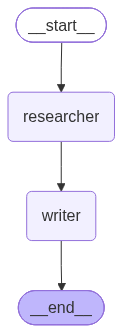

In [30]:
#Create Graph
builder =  StateGraph(AgentState)

#nodes
builder.add_node("researcher", research_agent)
builder.add_node("writer",writer_agent)

#edges
builder.set_entry_point("researcher")
builder.add_edge("researcher", "writer")
builder.add_edge("writer",END)

graph = builder.compile()

graph

In [29]:
response = graph.invoke({"messages":[("user","Can you give me the latest news of Korutla")]})

response["messages"].pretty_print()

BadRequestError: Error code: 400 - {'error': {'message': 'Tool choice is none, but model called a tool', 'type': 'invalid_request_error', 'code': 'tool_use_failed', 'failed_generation': '{"name": "search_web", "arguments": {"query": "Korutla news November 2026", "top_n": 10, "recency_days": 7}}'}}